# Do earnings-call text and audio predict post-call volatility?

Assignment 3, Advanced NLP. This notebook presents the modelling results. It reads saved
results only (`modelling/results/`), so it runs in seconds, locally or in Colab, without
the audio, the embeddings, or a GPU.

**Two rounds, each pre-registered:**

- **Round 1** (`docs/plans/2026-10-07-modelling-design.md`): an ablation ladder. Past
  volatility, then + text, + audio, + both. Hypotheses H1 (text helps) and H2 (audio
  adds to text).
- **Round 2** (`docs/plans/2026-10-07-round2-design.md`, committed before any round-2
  model ran): four follow-ups to round 1's negative audio result. Hypotheses H3–H5,
  plus a descriptive naive-split replication.

Each result below is labelled **confirmatory**, **exploratory** or **descriptive**.
Only confirmatory results are tests of a hypothesis fixed in advance.

In [1]:
# Setup: works locally (from modelling/ or modelling/notebooks/) and in Colab.
import json, os, subprocess, sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("advnlp_a3").exists():
    # Clone the repository; if it is private, upload modelling/results/ to /content instead.
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/bhutley/advnlp_a3.git"])

CANDIDATES = [Path("results"), Path("../results"), Path("advnlp_a3/modelling/results"),
              Path("modelling/results")]
RESULTS = next((p for p in CANDIDATES if (p / "metrics.csv").exists()), None)
assert RESULTS is not None, "results/ not found: run from modelling/ or upload modelling/results/"
R2 = RESULTS / "round2"

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.precision", 4)
VOL = ["vol_3", "vol_7", "vol_15", "vol_30"]
m1 = pd.read_csv(RESULTS / "metrics.csv")
m2 = pd.read_csv(R2 / "metrics.csv")
c1 = pd.read_csv(RESULTS / "comparisons.csv")
c2 = pd.read_csv(R2 / "comparisons.csv")
run1 = json.loads((RESULTS / "run.json").read_text())
run2 = json.loads((R2 / "run.json").read_text())
print(f"{run1['n_calls']} calls from {run1['n_firms']} firms; "
      f"{run1['repeats']} repeats × {run1['splits']} firm-grouped folds")

488 calls from 240 firms; 10 repeats × 5 firm-grouped folds


## Data and design

- **Sample:** 2017 S&P 500 earnings calls (Qin & Yang 2019) with usable prices and audio.
  Firms appear up to four times.
- **Targets:** log volatility of daily returns over the 3, 7, 15 and 30 trading days after
  the call (Qin & Yang's definition). Secondary: the sign of the abnormal return over
  [0,+1] and [0,+5].
- **Features:**
  - **past volatility** (the same horizon before the call)
  - **recording format** (calls come in 8 MP3 formats, which shape the audio features)
  - **text:** FinBERT call vectors and sentiment
  - **audio:** HuBERT call vectors (layer tuned in-fold) and four Praat prosody features
- **Validation:** firm-grouped, repeated 5-fold CV. All of a firm's calls fall on the same
  side of each split, because a firm's volatility persists and **its executive's voice is
  in every one of its calls**. Hyperparameters are tuned by an inner grouped CV on the
  training folds only.
- **Models:** ridge regression (logistic for direction) on standardised blocks, with
  in-fold PCA. Comparisons use a firm-clustered bootstrap of per-call squared errors,
  with Holm correction across the four horizons within each hypothesis.

## Round 1: the ablation ladder (confirmatory)

In [2]:
RUNG_NAMES = {"B0": "B0 raw past vol", "R1": "R1 past vol + format", "R2": "R2 + text",
              "R3": "R3 + audio", "R4": "R4 + text + audio", "R4_nopast": "R4 without past vol",
              "R4_prosus_finbert": "R4, ProsusAI FinBERT", "R4_wav2vec2": "R4, wav2vec2"}

def mse_table(m, rungs, names=RUNG_NAMES):
    t = m[m.metric == "mse"].pivot(index="rung", columns="target", values="mean")[VOL]
    sd = m[m.metric == "mse"].pivot(index="rung", columns="target", values="sd")[VOL]
    out = t.loc[rungs].round(3).astype(str) + " ± " + sd.loc[rungs].round(3).astype(str)
    return out.rename(index=names)

display(Markdown("**Out-of-fold MSE, mean ± SD over 10 repeats** (lower is better)"))
mse_table(m1, list(RUNG_NAMES))

**Out-of-fold MSE, mean ± SD over 10 repeats** (lower is better)

target,vol_3,vol_7,vol_15,vol_30
rung,,,,
B0 raw past vol,1.346 ± 0.0,0.661 ± 0.0,0.351 ± 0.0,0.185 ± 0.0
R1 past vol + format,0.511 ± 0.008,0.317 ± 0.004,0.196 ± 0.004,0.12 ± 0.003
R2 + text,0.48 ± 0.012,0.317 ± 0.01,0.2 ± 0.006,0.121 ± 0.005
R3 + audio,0.548 ± 0.01,0.336 ± 0.005,0.207 ± 0.004,0.125 ± 0.003
R4 + text + audio,0.526 ± 0.02,0.346 ± 0.012,0.216 ± 0.014,0.126 ± 0.006
R4 without past vol,0.524 ± 0.024,0.355 ± 0.017,0.235 ± 0.008,0.173 ± 0.008
"R4, ProsusAI FinBERT",0.525 ± 0.008,0.329 ± 0.012,0.202 ± 0.007,0.123 ± 0.004
"R4, wav2vec2",0.522 ± 0.018,0.334 ± 0.009,0.208 ± 0.007,0.125 ± 0.005


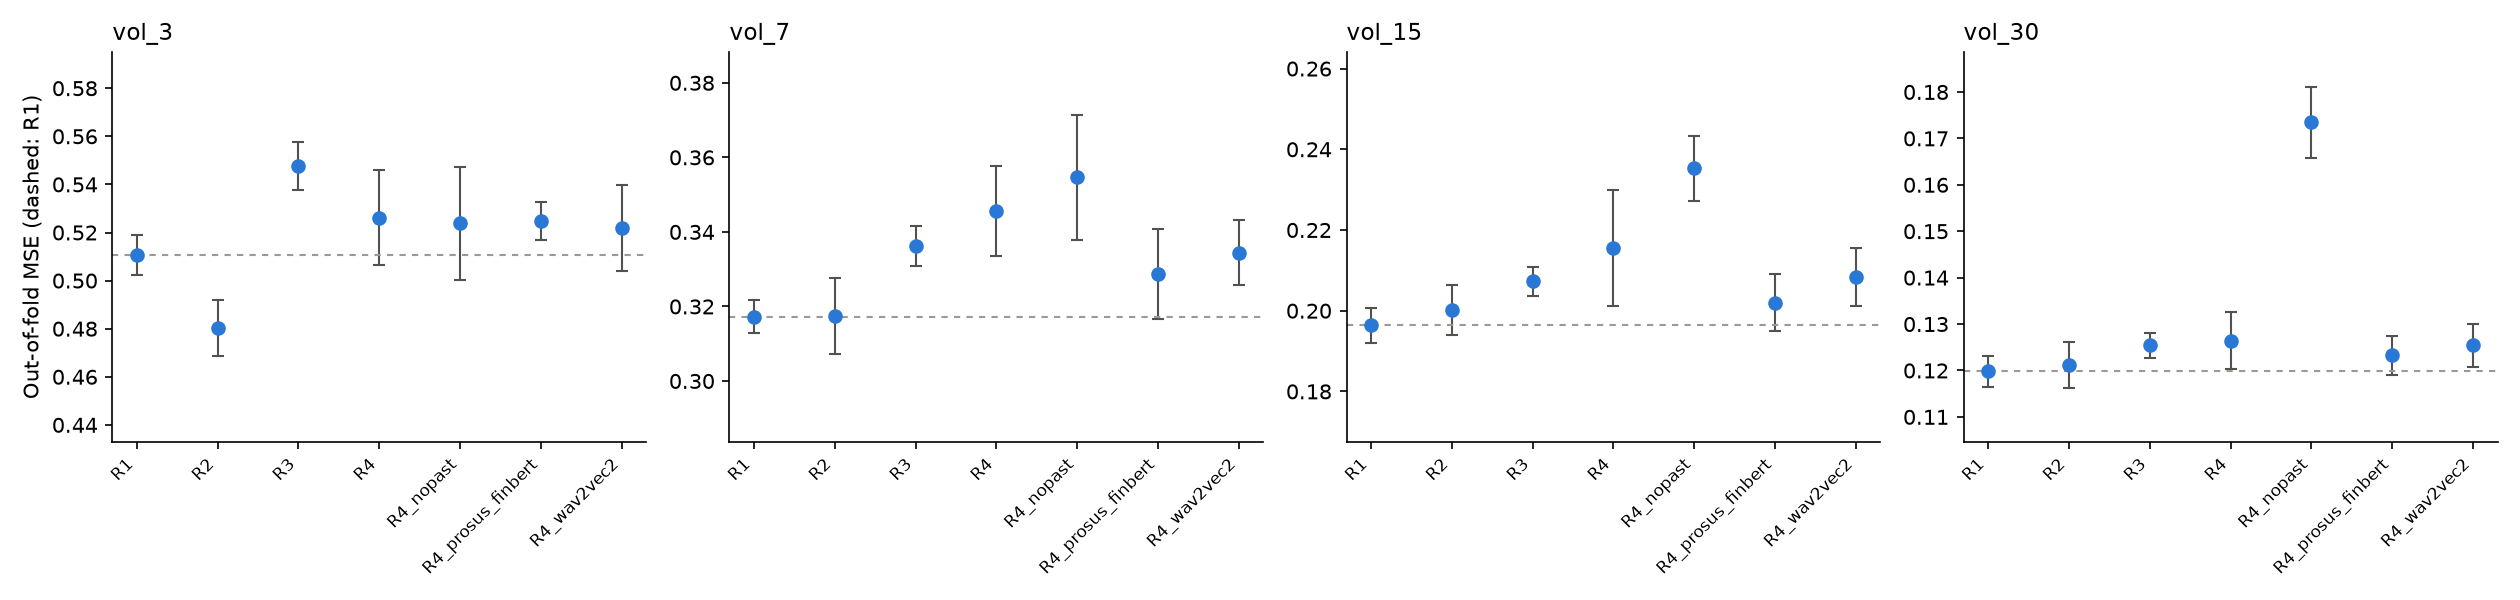

In [3]:
display(Image(str(RESULTS / "figures" / "mse_by_rung.png")))

In [4]:
def hypothesis_table(c, status="confirmatory"):
    t = c[c.status == status] if "status" in c else c[c.hypothesis.isin(["H1", "H2"])]
    t = t[["hypothesis", "target", "a", "b", "mean_diff", "ci_low", "ci_high", "p", "p_holm"]]
    return t.rename(columns={"mean_diff": "MSE(b) − MSE(a)"}).reset_index(drop=True)

display(Markdown("**H1: R2 beats R1 (text helps). H2: R4 beats R2 (audio adds to text).** "
                 "A positive difference means *a* is better; one-sided p, Holm across horizons."))
hypothesis_table(c1)

**H1: R2 beats R1 (text helps). H2: R4 beats R2 (audio adds to text).** A positive difference means *a* is better; one-sided p, Holm across horizons.

,hypothesis,target,a,b,MSE(b) − MSE(a),ci_low,ci_high,p,p_holm
0,H1,vol_3,R2,R1,0.0305,-0.0130,0.0734,0.0838,0.3352
1,H1,vol_7,R2,R1,-0.0002,-0.0224,0.0223,0.4938,1.0000
2,H1,vol_15,R2,R1,-0.0038,-0.0168,0.0084,0.7041,1.0000
3,H1,vol_30,R2,R1,-0.0014,-0.0091,0.0058,0.6229,1.0000
4,H2,vol_3,R4,R2,-0.0459,-0.0726,-0.0237,1.0000,1.0000
5,H2,vol_7,R4,R2,-0.0280,-0.0506,-0.0097,0.9998,1.0000
6,H2,vol_15,R4,R2,-0.0154,-0.0307,-0.0040,0.9986,1.0000
7,H2,vol_30,R4,R2,-0.0052,-0.0094,-0.0013,0.9945,1.0000


In [5]:
h = c1[c1.hypothesis.isin(["H1", "H2"])]
best = c1[(c1.hypothesis == "exploratory") & (c1.a == "R1") & (c1.b == "B0")]
gain = (best.mean_diff / (best.mean_diff + m1[(m1.metric == "mse") & (m1.rung == "R1")]
                          .set_index("target").loc[best.target, "mean"].values)).round(2)
display(Markdown(f'''**Round 1 findings**

- **Past volatility dominates.** Recalibrating it (R1: a linear fit with format) cuts MSE
  against raw past volatility (B0) by {gain.min():.0%}–{gain.max():.0%}.
- **H1 is not supported** at any horizon (smallest Holm p = {h[h.hypothesis == "H1"].p_holm.min():.2f}).
  Text's best case is 3 days.
- **H2 fails in the opposite direction:** adding audio *raises* MSE at every horizon
  (every CI below 0).'''))

**Round 1 findings**

- **Past volatility dominates.** Recalibrating it (R1: a linear fit with format) cuts MSE
  against raw past volatility (B0) by 35%–62%.
- **H1 is not supported** at any horizon (smallest Holm p = 0.34).
  Text's best case is 3 days.
- **H2 fails in the opposite direction:** adding audio *raises* MSE at every horizon
  (every CI below 0).

### Direction (secondary, exploratory)

In [6]:
auc = m1[m1.metric == "auc"].pivot(index="rung", columns="target", values="mean")
auc.loc[["B0", "R1", "R2", "R3", "R4"]].rename(index=RUNG_NAMES).round(3)

target,dir_0_1,dir_0_5
rung,,
B0 raw past vol,0.454,0.445
R1 past vol + format,0.480,0.474
R2 + text,0.563,0.570
R3 + audio,0.447,0.460
R4 + text + audio,0.534,0.544


Text (R2) reaches an AUC of about 0.57 for the sign of the abnormal return, in line with FinBERT tone's correlation with CARs. Audio adds nothing.

### Leakage checks

In [7]:
s = pd.read_csv(RESULTS / "sanity.csv")
perm = s[s.check == "permutation"].groupby("target").gain.agg(["mean", "max"]).loc[VOL]
group = s[s.check == "grouping"].set_index("target").loc[VOL, ["mse_grouped", "mse_ungrouped"]]
group["ungrouped lower by"] = 1 - group.mse_ungrouped / group.mse_grouped
display(Markdown("**Permutation null:** R1 − R4 MSE with shuffled targets. No spurious gain."))
display(perm.round(4))
display(Markdown("**Grouping effect** (audio-only R3, one repeat): ungrouped CV understates MSE."))
group.round(4)

**Permutation null:** R1 − R4 MSE with shuffled targets. No spurious gain.

,mean,max
target,,
vol_3,-0.0093,0.0086
vol_7,-0.0066,0.0040
vol_15,-0.0044,0.0023
vol_30,-0.0032,0.0027


**Grouping effect** (audio-only R3, one repeat): ungrouped CV understates MSE.

,mse_grouped,mse_ungrouped,ungrouped lower by
target,,,
vol_3,0.5374,0.5194,0.0334
vol_7,0.3373,0.3161,0.0629
vol_15,0.2099,0.1990,0.0520
vol_30,0.1264,0.1186,0.0622


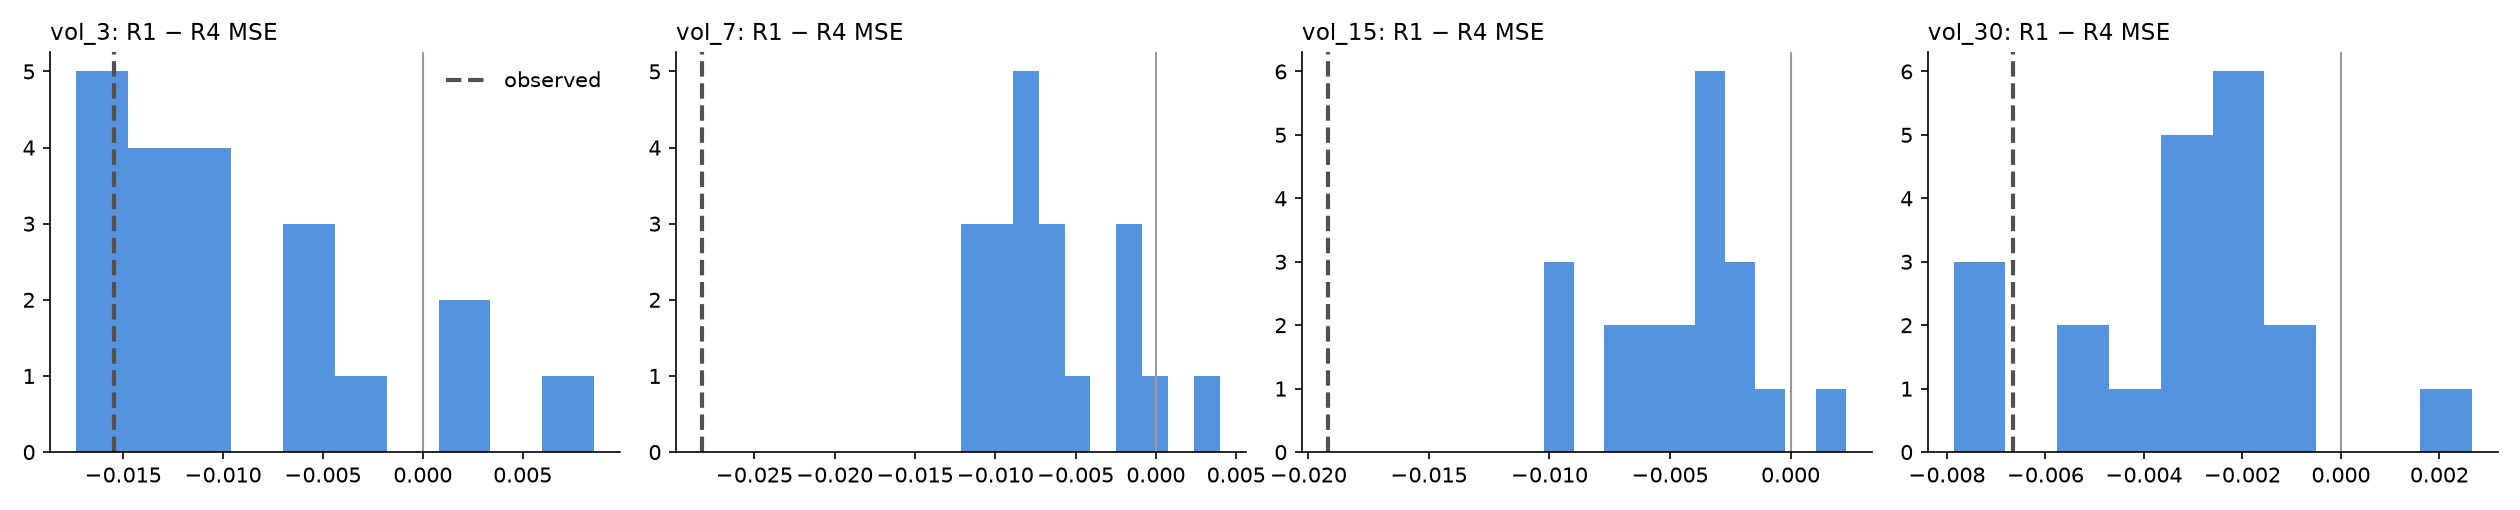

In [8]:
display(Image(str(RESULTS / "figures" / "permutation_null.png")))

### What the inner CV chose

In [9]:
oof1 = pd.read_parquet(RESULTS / "oof.parquet")
folds = oof1[oof1.target.isin(VOL)].drop_duplicates(["target", "rung", "repeat", "fold"])

def chosen(params):
    d = json.loads(params)
    k = "none" if any(v == "passthrough" for k_, v in d.items() if k_.endswith("__pca")) \
        else next((v for k_, v in d.items() if k_.endswith("n_components")), None)
    return pd.Series({"PCA k": k if k in (None, "none") else str(int(k)),
                      "audio layer": d.get("features__audio_emb__layer__layer")})

rows = []
for rung in ["R2", "R3", "R4"]:
    c = folds[folds.rung == rung].params.apply(chosen)
    rows.append({"rung": rung, "folds": len(c),
                 "most common k": c["PCA k"].astype(str).value_counts().idxmax(),
                 "share": c["PCA k"].astype(str).value_counts(normalize=True).max(),
                 "layers chosen": dict(c["audio layer"].dropna().astype(int).value_counts())})
pd.DataFrame(rows)

,rung,folds,most common k,share,layers chosen
0,R2,200,16,0.410,{}
1,R3,200,8,0.875,"{12: 73, 9: 48, 3: 44, 6: 35}"
2,R4,200,8,0.490,"{3: 102, 12: 43, 9: 29, 6: 26}"


For audio-only R3, the inner CV almost always chose the smallest PCA size, and its layer choices are spread out: the audio embeddings behave like noise.

## Round 2: four follow-ups (pre-registered)

| | Follow-up | Hypothesis |
|---|---|---|
| A | Prosody-only audio (`R1P`: past vol + format + 4 Praat features) | H3: R1P beats R1 |
| B | Format-residualised audio embeddings (`R3_resid`) | H4: R3_resid beats R3 |
| D | Attention over a call's sentences (`ATT`), against the same model with uniform weights (`UNI`) | H5: ATT beats UNI |
| C | The ladder under naive, ungrouped CV | descriptive |

In [10]:
R2_NAMES = RUNG_NAMES | {"R1P": "R1P = R1 + prosody", "R3_resid": "R3 format-residualised",
                        "UNI": "UNI uniform sentences", "ATT": "ATT attention"}
display(Markdown("**Out-of-fold MSE, mean ± SD** (R1–R4 from round 1, on the same splits)"))
mse_table(m2, ["R1", "R2", "R3", "R4", "R1P", "R3_resid", "UNI", "ATT"], R2_NAMES)

**Out-of-fold MSE, mean ± SD** (R1–R4 from round 1, on the same splits)

target,vol_3,vol_7,vol_15,vol_30
rung,,,,
R1 past vol + format,0.511 ± 0.008,0.317 ± 0.004,0.196 ± 0.004,0.12 ± 0.003
R2 + text,0.48 ± 0.012,0.317 ± 0.01,0.2 ± 0.006,0.121 ± 0.005
R3 + audio,0.548 ± 0.01,0.336 ± 0.005,0.207 ± 0.004,0.125 ± 0.003
R4 + text + audio,0.526 ± 0.02,0.346 ± 0.012,0.216 ± 0.014,0.126 ± 0.006
R1P = R1 + prosody,0.52 ± 0.009,0.324 ± 0.004,0.2 ± 0.004,0.122 ± 0.003
R3 format-residualised,0.549 ± 0.012,0.339 ± 0.004,0.207 ± 0.006,0.126 ± 0.003
UNI uniform sentences,0.523 ± 0.007,0.338 ± 0.006,0.218 ± 0.006,0.132 ± 0.005
ATT attention,0.549 ± 0.013,0.349 ± 0.009,0.23 ± 0.007,0.151 ± 0.005


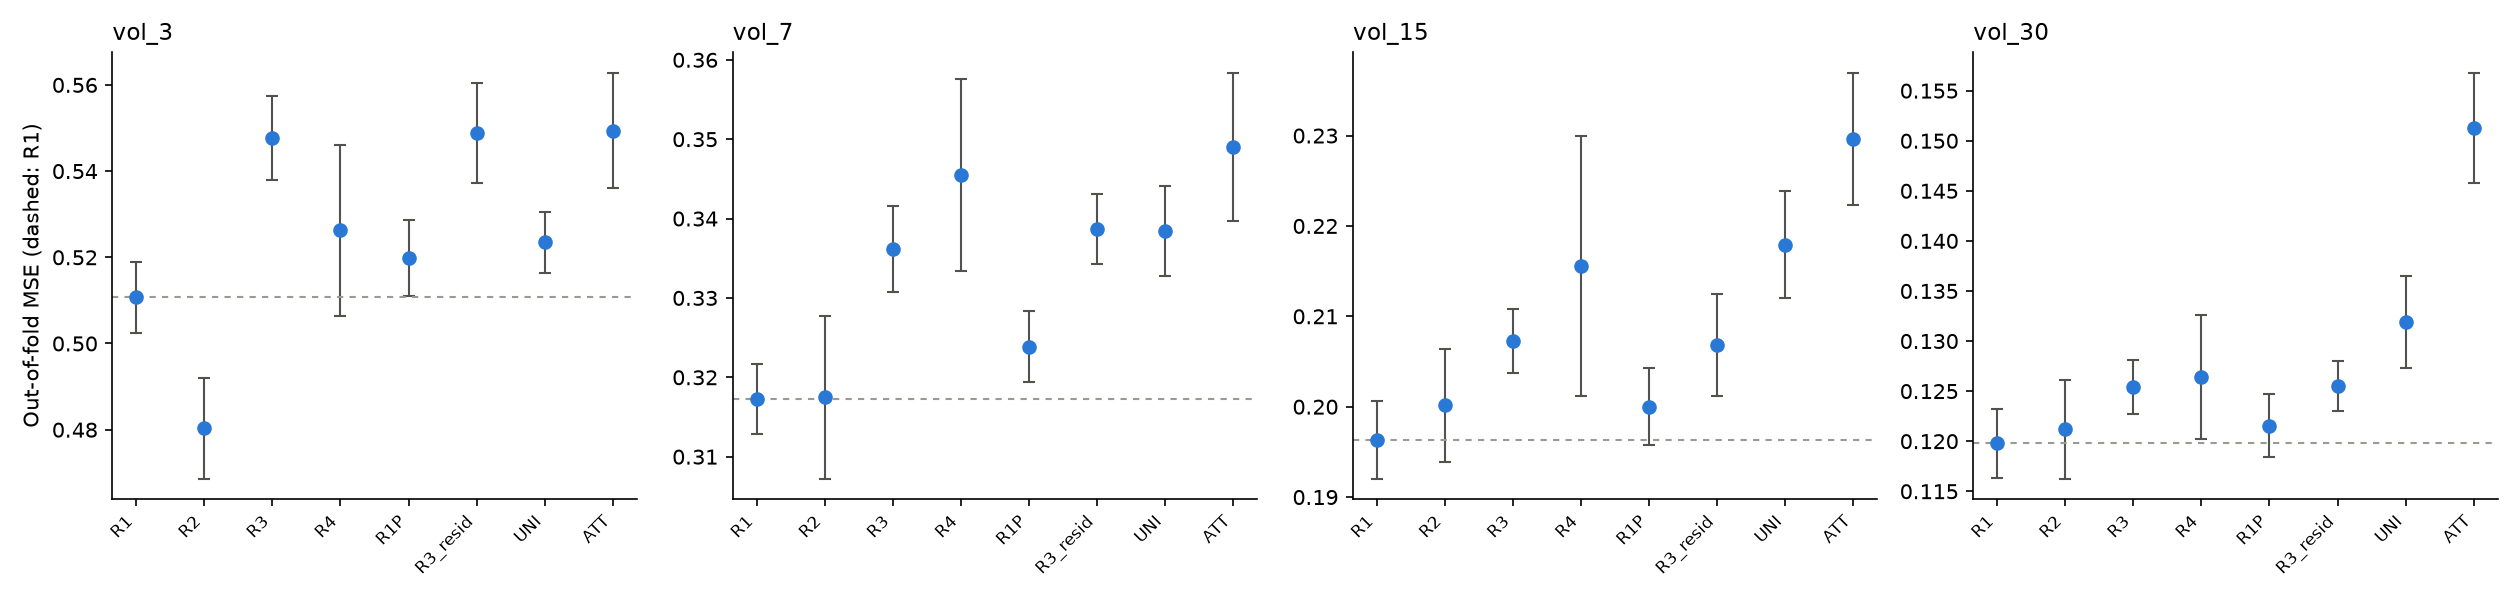

,hypothesis,target,a,b,MSE(b) − MSE(a),ci_low,ci_high,p,p_holm
0,H3,vol_3,R1P,R1,-0.0091,-0.0143,-0.0040,0.9999,1.0000
1,H3,vol_7,R1P,R1,-0.0066,-0.0101,-0.0032,1.0000,1.0000
2,H3,vol_15,R1P,R1,-0.0037,-0.0057,-0.0018,1.0000,1.0000
3,H3,vol_30,R1P,R1,-0.0018,-0.0030,-0.0006,0.9988,1.0000
4,H4,vol_3,R3_resid,R3,-0.0011,-0.0053,0.0031,0.7010,1.0000
5,H4,vol_7,R3_resid,R3,-0.0025,-0.0056,0.0005,0.9480,1.0000
6,H4,vol_15,R3_resid,R3,0.0004,-0.0008,0.0016,0.2411,0.9643
7,H4,vol_30,R3_resid,R3,-0.0001,-0.0009,0.0007,0.6086,1.0000
8,H5,vol_3,ATT,UNI,-0.0260,-0.0391,-0.0143,1.0000,1.0000
9,H5,vol_7,ATT,UNI,-0.0106,-0.0183,-0.0031,0.9977,1.0000


In [11]:
display(Image(str(R2 / "figures" / "mse_round2.png")))
hypothesis_table(c2)

In [12]:
h = c2[c2.status == "confirmatory"]
summary = h.groupby("hypothesis").agg(supported=("p_holm", lambda p: int((p < 0.05).sum())),
                                       below_zero=("ci_high", lambda x: int((x < 0).sum())))
display(Markdown(f'''**Round 2 findings**

- **None of H3–H5 is supported at any horizon** (horizons with Holm p < 0.05:
  {", ".join(f"{k} {v}" for k, v in summary.supported.items())}).
- **H3:** prosody alone makes predictions slightly *worse*: its CI lies below 0 at
  {summary.loc["H3", "below_zero"]} of 4 horizons.
- **H4:** removing format-predictable variance changes nothing, so **the format confound
  does not explain audio's harm**.
- **H5:** attention is *worse* than uniform pooling at {summary.loc["H5", "below_zero"]} of
  4 horizons.'''))

**Round 2 findings**

- **None of H3–H5 is supported at any horizon** (horizons with Holm p < 0.05:
  H3 0, H4 0, H5 0).
- **H3:** prosody alone makes predictions slightly *worse*: its CI lies below 0 at
  4 of 4 horizons.
- **H4:** removing format-predictable variance changes nothing, so **the format confound
  does not explain audio's harm**.
- **H5:** attention is *worse* than uniform pooling at 4 of
  4 horizons.

In [13]:
oof2 = pd.read_parquet(R2 / "oof.parquet")
wd = oof2[oof2.rung == "ATT"].drop_duplicates(["target", "repeat", "fold"]).params \
    .map(lambda p: json.loads(p)["weight_decay"]).value_counts()
display(Markdown(f"ATT chose the largest pre-registered weight decay (1.0) in "
                 f"{wd.get(1.0, 0)} of {wd.sum()} folds: the data asks for more shrinkage than "
                 "the grid allowed, i.e. for a smaller model. Extending the grid now would be "
                 "a post-hoc change, so H5 stands as run."))

ATT chose the largest pre-registered weight decay (1.0) in 189 of 200 folds: the data asks for more shrinkage than the grid allowed, i.e. for a smaller model. Extending the grid now would be a post-hoc change, so H5 stands as run.

### C: what a naive split would have shown (descriptive)

In [14]:
naive = pd.DataFrame({
    "grouped": m2[(m2.metric == "mse") & m2.rung.isin(["R1", "R2", "R3", "R4"])]
        .set_index(["target", "rung"])["mean"],
    "naive": m2[(m2.metric == "mse") & m2.rung.str.endswith("_naive") & (m2.rung != "B0_naive")]
        .assign(rung=lambda d: d.rung.str.removesuffix("_naive")).set_index(["target", "rung"])["mean"],
}).loc[VOL]
naive["naive lower by"] = 1 - naive.naive / naive.grouped
naive.round(4)

grouped   naive  naive lower by
target rung                                 
vol_3  R1     0.5108  0.5072          0.0069
       R2     0.4803  0.4590          0.0443
       R3     0.5477  0.5309          0.0307
       R4     0.5262  0.4865          0.0755
vol_7  R1     0.3173  0.3156          0.0053
       R2     0.3175  0.3023          0.0478
       R3     0.3362  0.3282          0.0238
       R4     0.3455  0.3196          0.0752
vol_15 R1     0.1963  0.1967         -0.0020
       R2     0.2002  0.1939          0.0314
       R3     0.2073  0.2047          0.0125
       R4     0.2155  0.2066          0.0416
vol_30 R1     0.1198  0.1202         -0.0037
       R2     0.1212  0.1199          0.0104
       R3     0.1254  0.1249          0.0041
       R4     0.1264  0.1250          0.0110

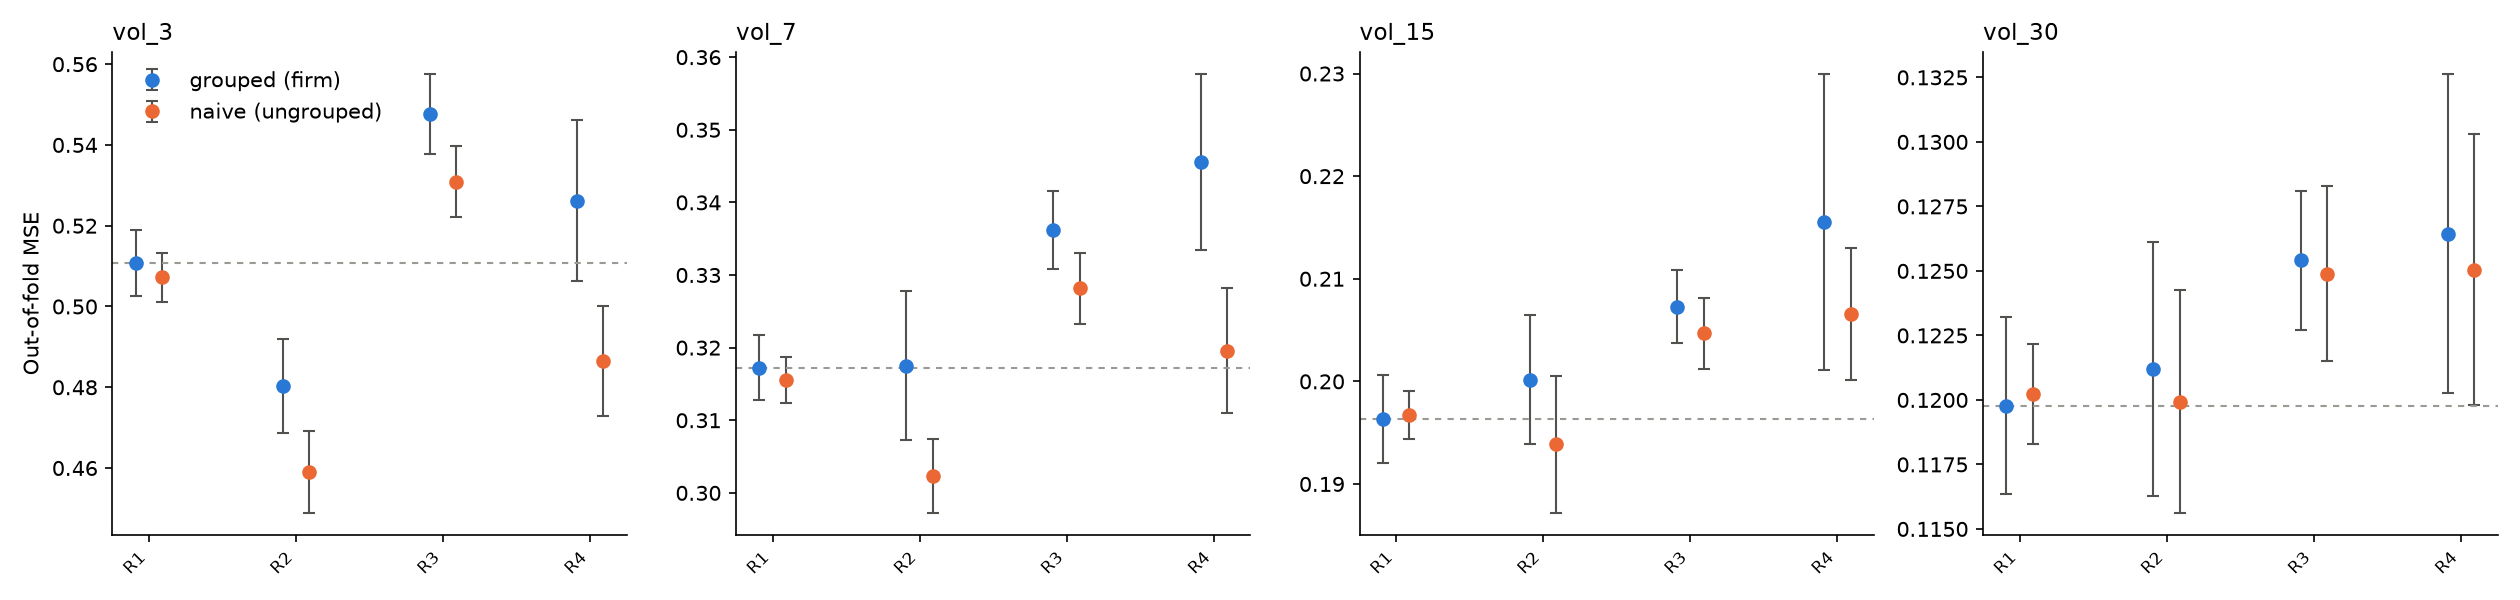

,hypothesis,target,mean_diff,ci_low,ci_high,p
0,H1_naive,vol_3,0.0482,0.0029,0.0939,0.0188
1,H1_naive,vol_7,0.0133,-0.0084,0.0355,0.1127
2,H1_naive,vol_15,0.0029,-0.0111,0.0165,0.3202
3,H1_naive,vol_30,0.0003,-0.0084,0.0082,0.4425
4,H2_naive,vol_3,-0.0275,-0.0490,-0.0080,0.9973
5,H2_naive,vol_7,-0.0172,-0.0357,-0.0020,0.9883
6,H2_naive,vol_15,-0.0127,-0.0238,-0.0032,0.9970
7,H2_naive,vol_30,-0.0051,-0.0096,-0.0007,0.9876


**A naive split manufactures a "significant" text result.** With ungrouped CV,
text beats past volatility at 3 days with p = 0.019 (CI 0.003 to
0.094). With firm-grouped CV, the same comparison has Holm p =
0.34. Naive splitting lowers MSE for the embedding rungs but barely for R1,
which is consistent with the embeddings identifying the firm or speaker.

In [15]:
display(Image(str(R2 / "figures" / "naive_vs_grouped.png")))
d = c2[c2.status == "descriptive"]
display(d[["hypothesis", "target", "mean_diff", "ci_low", "ci_high", "p"]].reset_index(drop=True))
naive_h1 = d[(d.hypothesis == "H1_naive") & (d.target == "vol_3")].iloc[0]
grouped_h1 = c1[(c1.hypothesis == "H1") & (c1.target == "vol_3")].iloc[0]
display(Markdown(f'''**A naive split manufactures a "significant" text result.** With ungrouped CV,
text beats past volatility at 3 days with p = {naive_h1.p:.3f} (CI {naive_h1.ci_low:.3f} to
{naive_h1.ci_high:.3f}). With firm-grouped CV, the same comparison has Holm p =
{grouped_h1.p_holm:.2f}. Naive splitting lowers MSE for the embedding rungs but barely for R1,
which is consistent with the embeddings identifying the firm or speaker.'''))

### D: where attention looks

In [16]:
w = pd.read_parquet(R2 / "attention_weights.parquet")
top1 = w[w["rank"] == 1].groupby("modality").weight.describe()[["mean", "50%", "max"]]
display(Markdown("**Weight on each call's top sentence** (uniform over a median call ≈ 1/153 ≈ 0.007):"))
display(top1.round(3))

# Example sentences need the transcripts, which only exist locally.
DATASET = Path.home() / "var/data/earnings_calls/ACL19_Release"
if DATASET.exists():
    # Distinct calls with at least 20 sentences (a 1-sentence call has weight 1 trivially),
    # ranked by their top text sentence's weight averaged over repeats.
    def lines_of(event_id):
        return [l.strip() for l in (DATASET / event_id / "TextSequence.txt")
                .read_text(errors="replace").splitlines() if l.strip()]
    top = (w[(w.modality == "text") & (w["rank"] == 1) & (w.target == "vol_3")]
           .groupby(["event_id", "sent_idx"]).weight.mean().reset_index())
    top = top[top.event_id.map(lambda e: len(lines_of(e)) >= 20)]
    for _, r in top.sort_values("weight", ascending=False).drop_duplicates("event_id").head(4).iterrows():
        n = len(lines_of(r.event_id))
        print(f"{r.event_id} ({n} sentences; weight {r.weight:.2f} vs uniform {1/n:.3f}):\n"
              f"    {lines_of(r.event_id)[r.sent_idx]}")
else:
    print("Transcripts not available here; example sentences are shown only when run locally.")

**Weight on each call's top sentence** (uniform over a median call ≈ 1/153 ≈ 0.007):

,mean,50%,max
modality,,,
audio,0.045,0.015,1.0
text,0.050,0.033,1.0


Incyte_20170801 (29 sentences; weight 0.30 vs uniform 0.034):
    The second quarter was very strong
Advanced Micro Devices Inc_20171024 (61 sentences; weight 0.22 vs uniform 0.016):
    Hi, Mark
Chevron Corp._20170127 (56 sentences; weight 0.20 vs uniform 0.018):
    2016 was our 29th consecutive year of an annual per share increase
Seagate Technology_20170426 (27 sentences; weight 0.20 vs uniform 0.037):
    Our March quarter results continue to reflect strong execution of our business model objectives and our ability to generate strong cash flow from our Storage portfolio


Attention is moderately peaked, but some of the sentences it favours are short and generic (greetings, transitions). That is consistent with H5's result: the learned weights fit noise more than signal at this sample size.

## Conclusions

1. **Past volatility, recalibrated, is the strongest predictor.** None of the text or
   audio models beats it reliably in a firm-grouped design.
2. **Text has at most a weak, short-horizon signal:** about 6% lower 3-day MSE (not
   significant), and a direction AUC of about 0.57.
3. **No way of using audio helped:** call-level embeddings, prosody, format-residualised
   embeddings, or attention over sentences. Format was not the reason.
4. **The evaluation design matters.** A naive split makes text look significant and audio
   look less harmful. Repeat firms (and repeat voices) must be kept apart.

## Caveats

- **One year (2017), about 490 calls:** small for 768-dimension representations. Larger
  samples could change the audio picture.
- **Date clustering:** calls bunch in earnings seasons, and the firm-clustered bootstrap
  doesn't account for correlation across firms on the same dates.
- **Volatility windows count trading days;** Qin & Yang describe calendar days.
- **The clips are a single executive's remarks,** not the full call (no analyst Q&A).
- **Recording format** is controlled as a covariate. It is encoded in the audio embeddings
  and weakly related to 30-day volatility.
- **The audio models** are pretrained only (not fine-tuned), on telephone-to-broadcast
  quality MP3s.